In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## radar-chart

**Figure 1: Accuracy (%) of three 8–9B models on six benchmarks.** Labels give Ours-8B's accuracy on each benchmark. Ours-8B has the most balanced profile, best on five of six benchmarks and within 2.9 points of the best on MMLU, with its largest leads on MATH (41.5 vs. 36.6) and GSM8K (79.6 vs. 75.1).

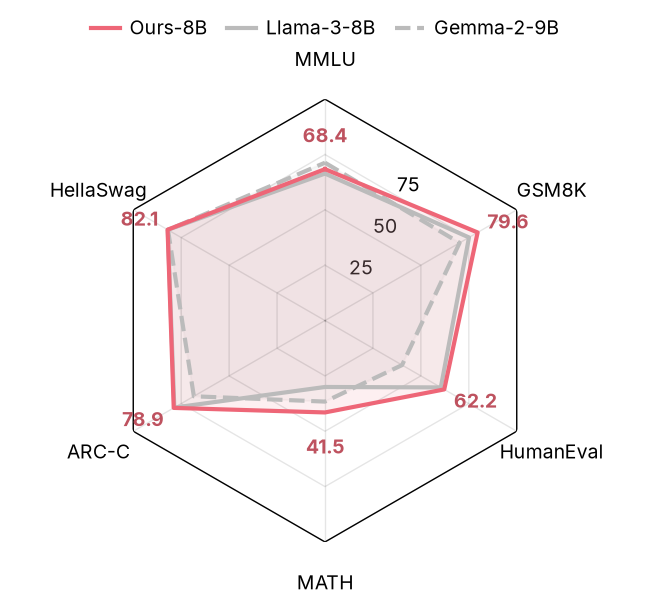

In [2]:
with open("../radar-chart.json") as f:
    data = json.load(f)
names = data["benchmarks"]
scores = data["scores"]

n = len(names)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
loop = np.r_[angles, angles[:1]]
rings = [25, 50, 75, 100]

fig, ax = plt.subplots(figsize=(3.25, 3.25), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

ax.grid(False)
ax.spines["polar"].set_visible(False)
for r in rings:
    ax.plot(loop, [r] * (n + 1), color=colors["ink"], alpha=0.1, linewidth=0.5)
for a in angles:
    ax.plot([a, a], [0, rings[-1]], color=colors["ink"], alpha=0.1, linewidth=0.5)
ax.plot(loop, [rings[-1]] * (n + 1), color=colors["ink"], linewidth=0.5)
ax.set_ylim(0, rings[-1])

for name, linestyle in [("Llama-3-8B", "-"), ("Gemma-2-9B", "--")]:
    values = scores[name]
    ax.plot(loop, np.r_[values, values[:1]], color=colors["neutral"], linestyle=linestyle, label=name)
    ax.fill(angles, values, color=colors["neutral"], alpha=0.1)

ours = scores["Ours-8B"]
ax.plot(loop, np.r_[ours, ours[:1]], color=colors["ours"], label="Ours-8B")
ax.fill(angles, ours, color=colors["ours"], alpha=0.1)
for a, v in zip(angles, ours):
    ha = "left" if np.sin(a) > 0.1 else "right" if np.sin(a) < -0.1 else "center"
    va = "bottom" if np.cos(a) > 0.9 else "top" if np.cos(a) < -0.9 else "center"
    ax.annotate(f"{v:.1f}", (a, v), xytext=(4 * np.sin(a), 8 * np.cos(a)), textcoords="offset points",
                color=darken(colors["ours"]), fontweight="bold", ha=ha, va=va)

ax.set_xticks(angles, labels=names)
ax.tick_params(axis="x", pad=6)
# Polygon rings sit at r·cos(π/n) halfway between spokes, where the ring labels are placed.
ax.set_yticks([r * np.cos(np.pi / n) for r in rings[:-1]], labels=rings[:-1])
ax.set_rlabel_position(180 / n)

handles, labels = ax.get_legend_handles_labels()
order = [2, 0, 1]
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc="outside upper center", ncol=3, frameon=False)

fit_height(fig, ax)
fig.savefig("radar-chart.pdf")
fig.savefig("radar-chart.png")
plt.show()